# Crypto Volatility Project — Exploratory Data Analysis (EDA)

This notebook provides a reproducible exploration of cryptocurrency price, return, and volatility data. It is designed to address the main issues identified in the earlier notebook:

- Use portable file paths rather than machine-specific absolute paths.
- Preserve expected missing values created by returns and rolling windows; do not delete the Aptos row arbitrarily.
- Investigate extreme returns without automatically removing them.
- Create a one-observation-ahead volatility target **within each cryptocurrency**.
- Make the time-based train/test cutoff explicit and avoid mixing future observations into training.
- Keep exploratory analysis separate from final model fitting and dashboard deployment.

**Expected input:** a cleaned CSV with columns such as `open`, `high`, `low`, `close`, `volume`, `marketCap`, `timestamp`, `crypto_name`, and optionally existing engineered columns.

> Set `DATA_PATH` in the next cell if your CSV is stored elsewhere. This notebook does not modify the source CSV.

## 1. Imports and configuration

In [4]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 100)
sns.set_theme()

# Edit this path if needed. Relative paths are resolved from the notebook's working directory.
DATA_PATH = Path("C:/Users/Mayur/CRYPTOCURRECNY VOLATILITY PROJECT/data/processed/cleaned.csv")

# Optional fallback locations (useful if the notebook is run from the project root).
CANDIDATE_PATHS = [
    DATA_PATH,
    Path("data/cleaned.csv"),
    Path("C:/Users/Mayur/CRYPTOCURRECNY VOLATILITY PROJECT/data/processed/cleaned.csv"),
]

existing_paths = [p for p in CANDIDATE_PATHS if p.exists()]
if not existing_paths:
    raise FileNotFoundError(
        "Could not find cleaned.csv. Update DATA_PATH to the location of your cleaned dataset."
    )

DATA_PATH = existing_paths[0]
print(f"Loading data from: {DATA_PATH.resolve()}")

Loading data from: C:\Users\Mayur\CRYPTOCURRECNY VOLATILITY PROJECT\data\processed\cleaned.csv


## 2. Load data and inspect its structure

In [5]:
df = pd.read_csv(DATA_PATH)

print("Shape:", df.shape)
display(df.head())
print("\\nColumns:")
print(df.columns.tolist())

Shape: (72946, 17)


,Unnamed: 0,open,high,low,close,volume,marketCap,timestamp,crypto_name,date,normalized_close,daily_return,volatility_7d,volatility_30d,volatility_7d_pct,volatility_30d_pct,target_volatility
0,44644,0.000000,0.516571,0.000000,0.516571,0.000000,0.000000e+00,2020-10-02 23:59:59.999000+00:00,Aave,2020-10-02,100.000000,NaN,NaN,NaN,NaN,NaN,NaN
1,44709,0.523836,65.305938,0.523801,53.151488,0.000000,0.000000e+00,2020-10-03 23:59:59.999000+00:00,Aave,2020-10-03,10289.280945,101.892809,NaN,NaN,NaN,NaN,NaN
2,44780,53.179858,55.070355,50.688990,52.675035,0.000000,0.000000e+00,2020-10-04 23:59:59.999000+00:00,Aave,2020-10-04,10197.047274,-0.008964,NaN,NaN,NaN,NaN,NaN
3,44826,52.675035,55.112358,49.787900,53.219243,0.000000,8.912813e+07,2020-10-05 23:59:59.999000+00:00,Aave,2020-10-05,10302.397270,0.010331,NaN,NaN,NaN,NaN,NaN
4,44843,53.291969,53.402270,40.734578,42.401599,583091.459763,7.101144e+07,2020-10-06 23:59:59.999000+00:00,Aave,2020-10-06,8208.273727,-0.203266,NaN,NaN,NaN,NaN,NaN


\nColumns:
['Unnamed: 0', 'open', 'high', 'low', 'close', 'volume', 'marketCap', 'timestamp', 'crypto_name', 'date', 'normalized_close', 'daily_return', 'volatility_7d', 'volatility_30d', 'volatility_7d_pct', 'volatility_30d_pct', 'target_volatility']


In [6]:
# Inspect data types and missing values.
display(df.dtypes.rename("dtype").to_frame())
missing = df.isna().sum().sort_values(ascending=False)
display(missing[missing > 0].to_frame("missing_count"))

,dtype
Unnamed: 0,int64
open,float64
high,float64
low,float64
close,float64
volume,float64
marketCap,float64
timestamp,object
crypto_name,object
date,object


,missing_count
volatility_30d,1651
volatility_30d_pct,1651
target_volatility,386
volatility_7d_pct,386
volatility_7d,386
daily_return,56


In [7]:
# Check whether each coin/date combination is unique.
required = {"crypto_name", "date"}
missing_required = required - set(df.columns)
if missing_required:
    raise ValueError(f"Required columns missing: {missing_required}")

df["date"] = pd.to_datetime(df["date"], errors="coerce")
print("Invalid dates:", df["date"].isna().sum())
print("Duplicate coin-date rows:", df.duplicated(["crypto_name", "date"]).sum())

Invalid dates: 0
Duplicate coin-date rows: 0


## 3. Prepare chronological data safely

Sort by cryptocurrency and date before computing within-coin changes. This ordering is appropriate for rolling features and the one-step-ahead target. It is **not by itself** a global chronological train/test split; a date cutoff is used later.

In [8]:
df = df.dropna(subset=["crypto_name", "date"]).copy()
df = df.sort_values(["crypto_name", "date"]).reset_index(drop=True)

# Check date gaps per coin. A next-row target means the next available observation,
# which may not be the next calendar day if dates are missing.
date_gaps = (
    df.groupby("crypto_name")["date"]
      .diff()
      .dt.days
)
print("Rows with a gap greater than one calendar day:", int((date_gaps > 1).sum()))

Rows with a gap greater than one calendar day: 5581


## 4. Dataset coverage by cryptocurrency

,observations
crypto_name,
Bitcoin,3248
Litecoin,3248
XRP,3157
Dogecoin,3024
Monero,2866
Stellar,2791
Tether,2582
Ethereum,2424
Ethereum Classic,2072


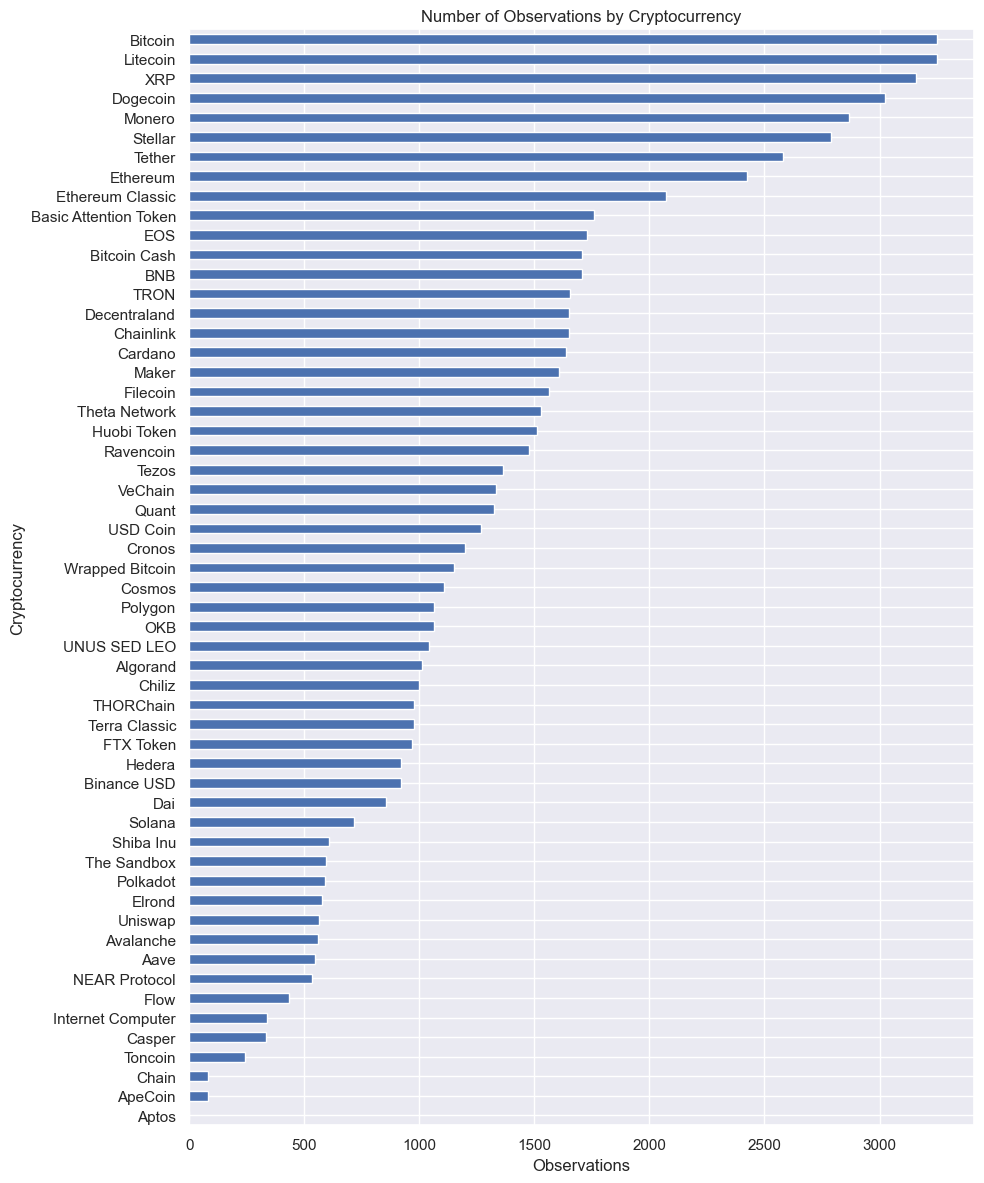

In [9]:
coin_counts = df["crypto_name"].value_counts().sort_values(ascending=False)
display(coin_counts.to_frame("observations"))

ax = coin_counts.sort_values().plot(kind="barh", figsize=(10, 12))
ax.set_title("Number of Observations by Cryptocurrency")
ax.set_xlabel("Observations")
ax.set_ylabel("Cryptocurrency")
plt.tight_layout()
plt.show()

## 5. Price exploration

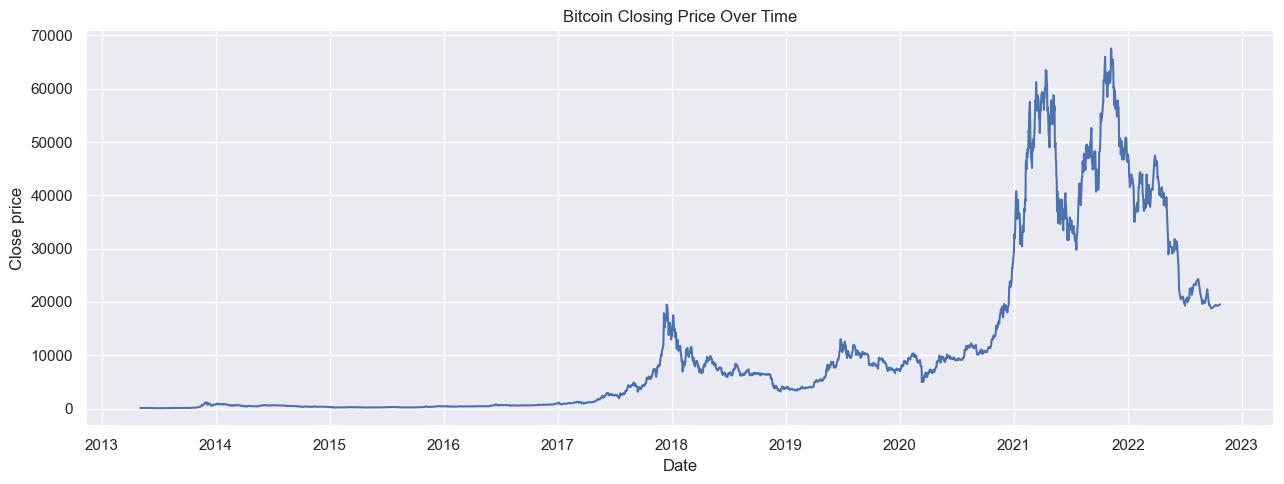

In [10]:
# Plot Bitcoin's closing price if Bitcoin is present.
if "close" in df.columns and (df["crypto_name"] == "Bitcoin").any():
    btc = df.loc[df["crypto_name"].eq("Bitcoin")].sort_values("date")
    plt.figure(figsize=(13, 5))
    plt.plot(btc["date"], btc["close"])
    plt.title("Bitcoin Closing Price Over Time")
    plt.xlabel("Date")
    plt.ylabel("Close price")
    plt.tight_layout()
    plt.show()
else:
    print("Bitcoin rows or close column not found.")

C:\Users\Mayur\AppData\Local\Temp\ipykernel_1692\1196143041.py:11: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


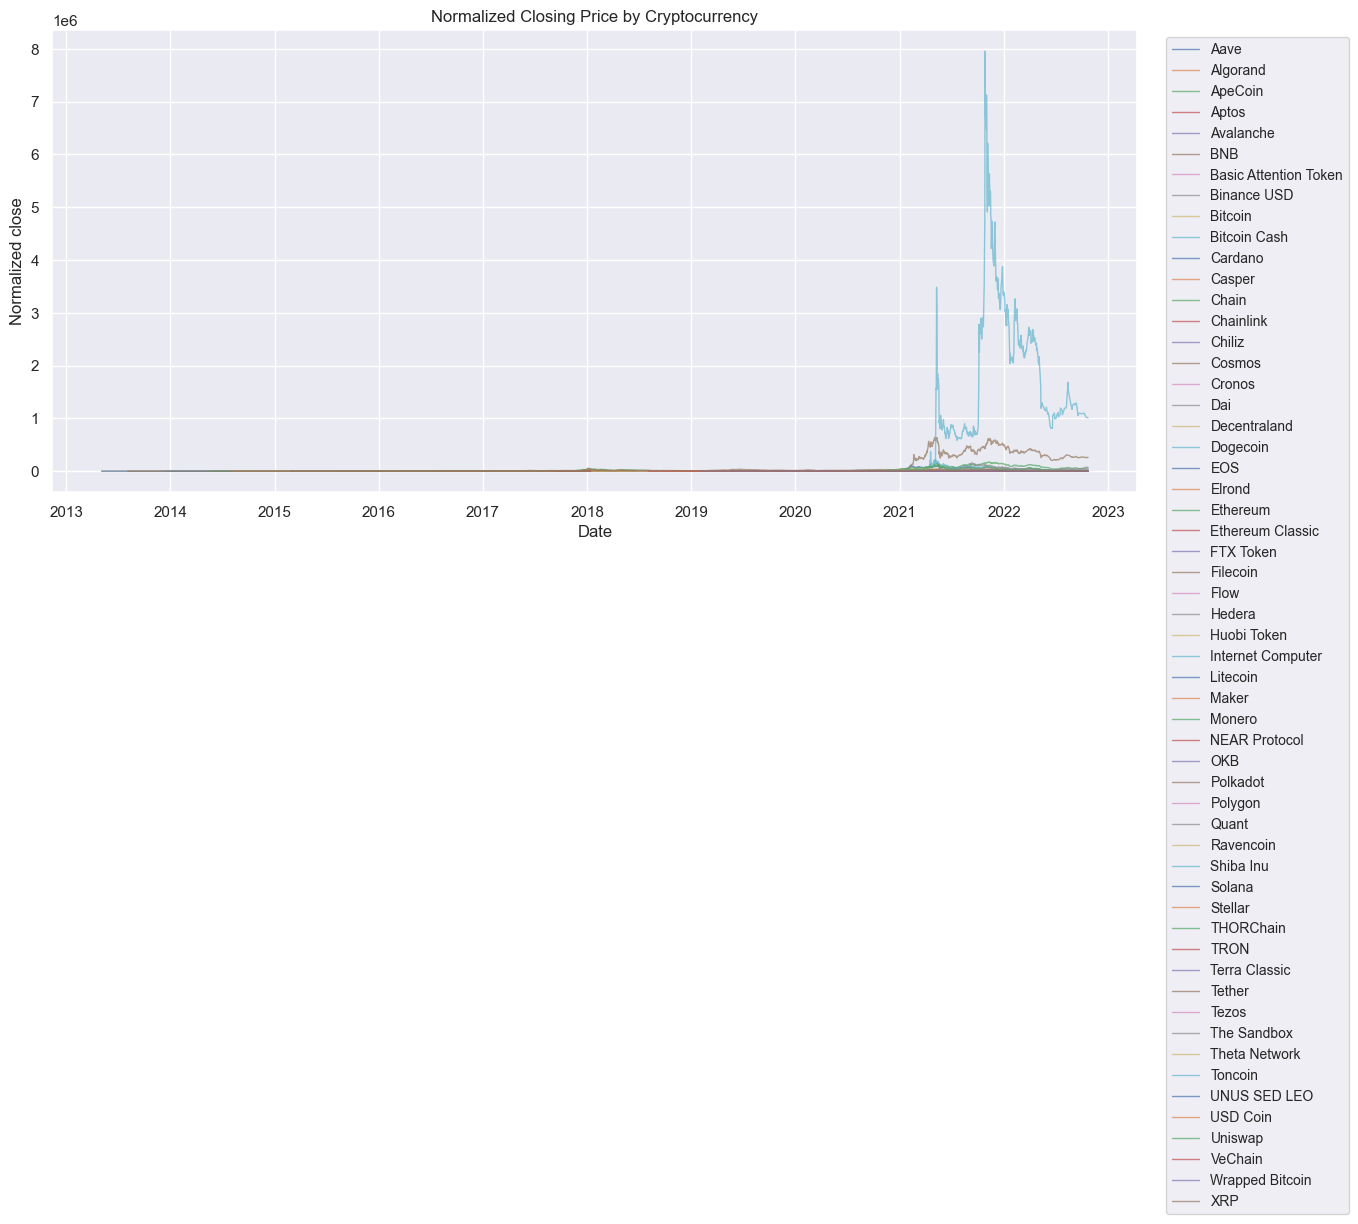

In [11]:
# Compare normalized prices if the field exists.
if "normalized_close" in df.columns:
    plt.figure(figsize=(14, 6))
    for coin, part in df.groupby("crypto_name", sort=False):
        part = part.sort_values("date")
        plt.plot(part["date"], part["normalized_close"], alpha=0.7, linewidth=1, label=coin)
    plt.title("Normalized Closing Price by Cryptocurrency")
    plt.xlabel("Date")
    plt.ylabel("Normalized close")
    plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize="small")
    plt.tight_layout()
    plt.show()
else:
    print("normalized_close not found; skipping normalized price comparison.")

## 6. Returns and outlier investigation

If `daily_return` already exists, use it. Otherwise, calculate it within each coin using `pct_change()`. Missing first returns are expected and are not removed from the main EDA dataset.

Extreme values are flagged for inspection—not automatically deleted. In particular, investigate whether unusual values are present in the raw source and whether date gaps or token denomination changes explain them.

In [12]:
if "daily_return" not in df.columns:
    df["daily_return"] = df.groupby("crypto_name", sort=False)["close"].pct_change()

return_summary = (
    df.groupby("crypto_name")["daily_return"]
      .agg(["count", "mean", "median", "std", "min", "max"])
      .sort_values("mean", ascending=False)
)
display(return_summary)

,count,mean,median,std,min,max
crypto_name,,,,,,
Shiba Inu,607,0.335689,0.000000,7.211544,-0.715255,177.327290
Aave,546,0.191208,0.003564,4.361258,-0.338302,101.892809
Toncoin,240,0.010473,-0.004157,0.124620,-0.238299,0.964938
Maker,1604,0.009945,-0.000395,0.280708,-0.558768,10.895575
The Sandbox,594,0.009783,-0.001469,0.113236,-0.368275,1.016227
THORChain,977,0.009506,0.000000,0.100172,-0.425036,0.551944
Polygon,1063,0.009411,0.000128,0.096355,-0.511156,0.645633
Quant,1324,0.008859,-0.003401,0.090156,-0.471269,0.697242
Solana,717,0.008668,0.001125,0.088701,-0.372088,0.472828


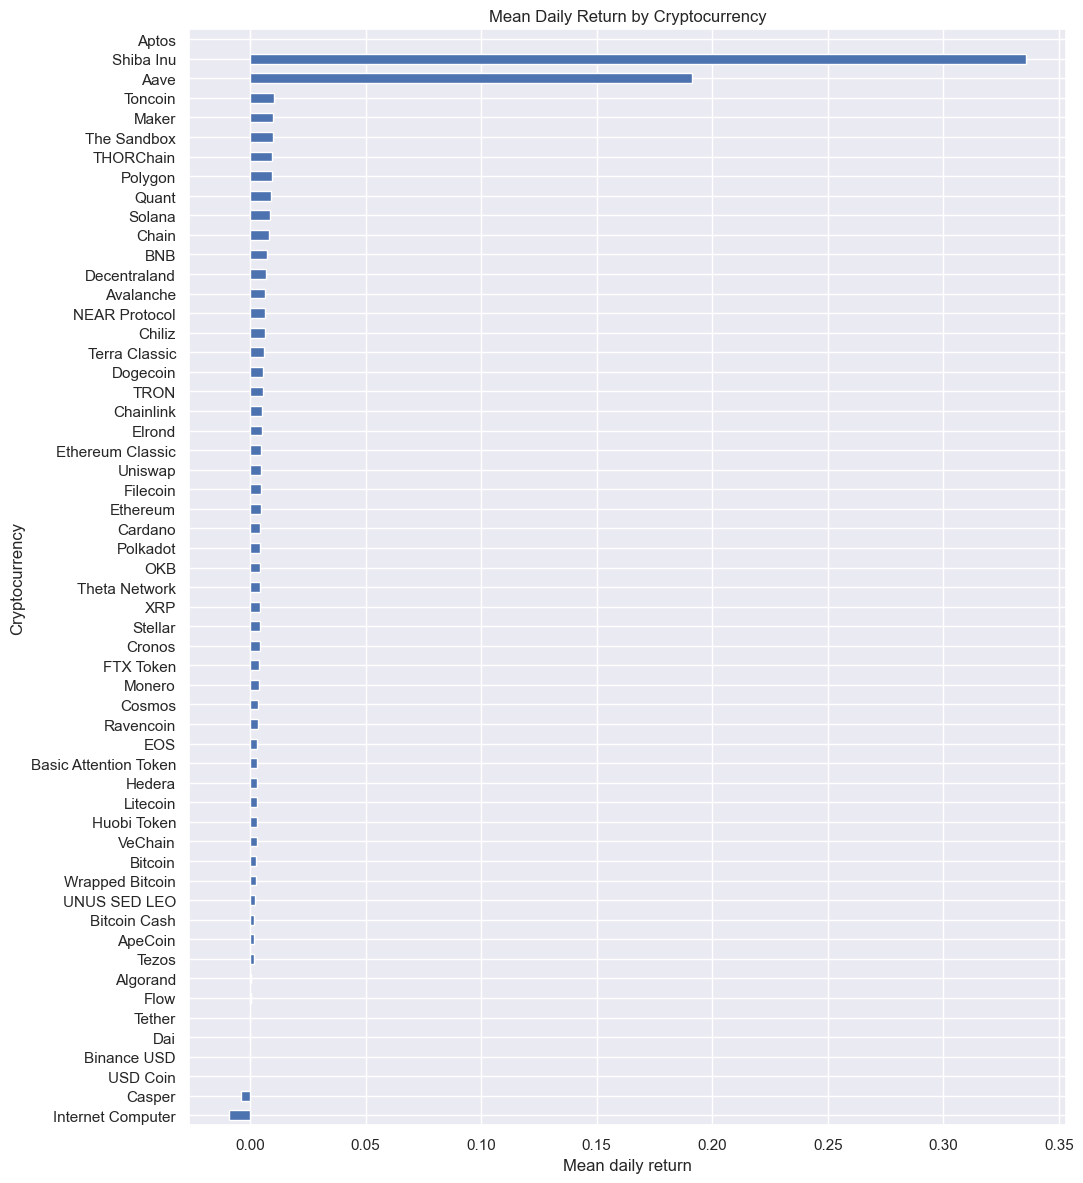

In [13]:
mean_returns = df.groupby("crypto_name")["daily_return"].mean().sort_values()
plt.figure(figsize=(11, 12))
mean_returns.plot(kind="barh")
plt.title("Mean Daily Return by Cryptocurrency")
plt.xlabel("Mean daily return")
plt.ylabel("Cryptocurrency")
plt.tight_layout()
plt.show()

In [14]:
# Inspect largest absolute returns across all coins.
return_cols = ["crypto_name", "date", "close", "daily_return"]
extremes = (
    df.loc[df["daily_return"].notna(), return_cols]
      .assign(abs_return=lambda x: x["daily_return"].abs())
      .nlargest(20, "abs_return")
)
display(extremes)

,crypto_name,date,close,daily_return,abs_return
50573,Shiba Inu,2021-01-31,3.000000e-08,177.327290,177.327290
1,Aave,2020-10-03,5.315149e+01,101.892809,101.892809
39876,Maker,2017-08-27,2.908480e+02,10.895575,10.895575
50666,Shiba Inu,2021-05-08,1.578000e-05,9.313725,9.313725
50429,Shiba Inu,2020-09-02,4.701900e-10,4.670405,4.670405
23649,Dogecoin,2021-01-28,3.408356e-02,3.555712,3.555712
28814,Ethereum Classic,2016-07-26,2.553480e+00,3.238831,3.238831
20872,Decentraland,2021-10-30,3.564692e+00,2.869134,2.869134
21063,Dogecoin,2013-12-19,1.162490e-03,2.214575,2.214575
50646,Shiba Inu,2021-04-17,1.980000e-06,1.911765,1.911765


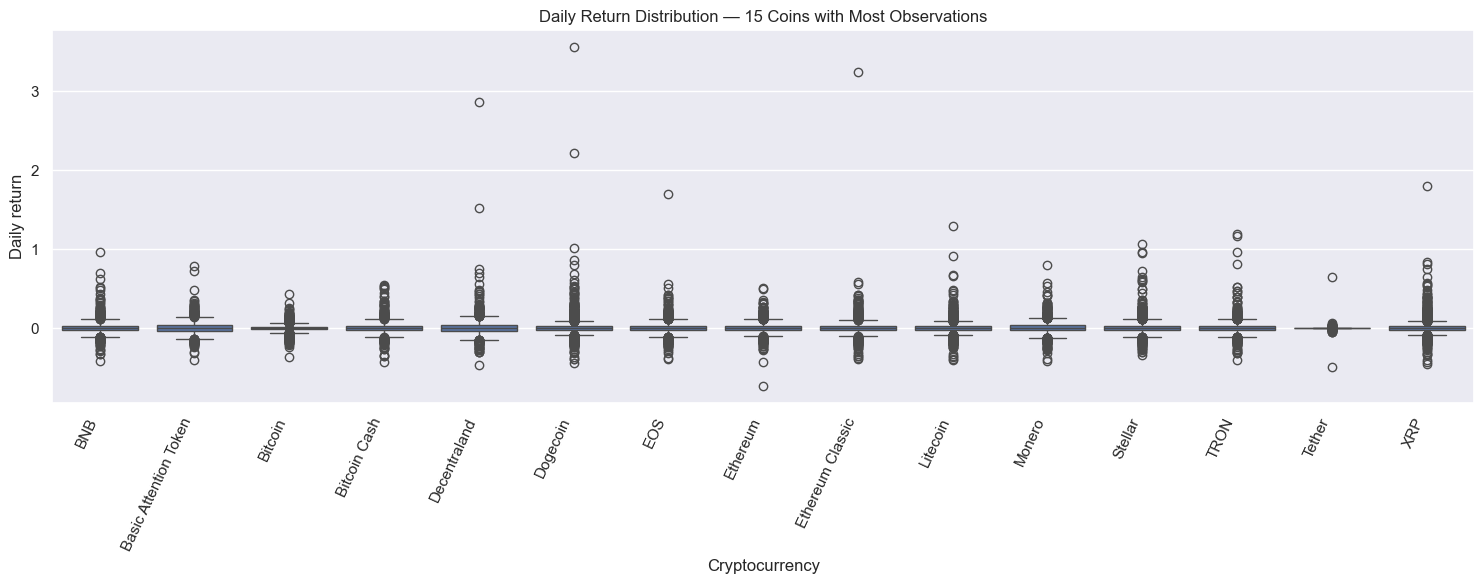

In [15]:
# Boxplot of returns by coin. A focused plot is often easier to read than dozens of categories.
top_coins = df["crypto_name"].value_counts().head(15).index
plt.figure(figsize=(15, 6))
sns.boxplot(data=df[df["crypto_name"].isin(top_coins)],
            x="crypto_name", y="daily_return", showfliers=True)
plt.title("Daily Return Distribution — 15 Coins with Most Observations")
plt.xlabel("Cryptocurrency")
plt.ylabel("Daily return")
plt.xticks(rotation=65, ha="right")
plt.tight_layout()
plt.show()

## 7. Rolling volatility

In [16]:
# Create rolling standard deviation of daily returns only if the columns are not already present.
# min_periods equals the window length so early missing values are expected.
if "volatility_7d" not in df.columns:
    df["volatility_7d"] = (
        df.groupby("crypto_name", sort=False)["daily_return"]
          .transform(lambda s: s.rolling(window=7, min_periods=7).std())
    )

if "volatility_30d" not in df.columns:
    df["volatility_30d"] = (
        df.groupby("crypto_name", sort=False)["daily_return"]
          .transform(lambda s: s.rolling(window=30, min_periods=30).std())
    )

vol_summary = df.groupby("crypto_name")[["volatility_7d", "volatility_30d"]].mean()
display(vol_summary.sort_values("volatility_7d", ascending=False))

,volatility_7d,volatility_30d
crypto_name,,
Shiba Inu,0.990753,1.951749
Aave,0.148969,0.117434
ApeCoin,0.125806,0.152320
Chain,0.105524,0.139314
Toncoin,0.093390,0.108181
The Sandbox,0.092159,0.102979
THORChain,0.090840,0.096098
NEAR Protocol,0.090317,0.095092
Filecoin,0.089102,0.096375


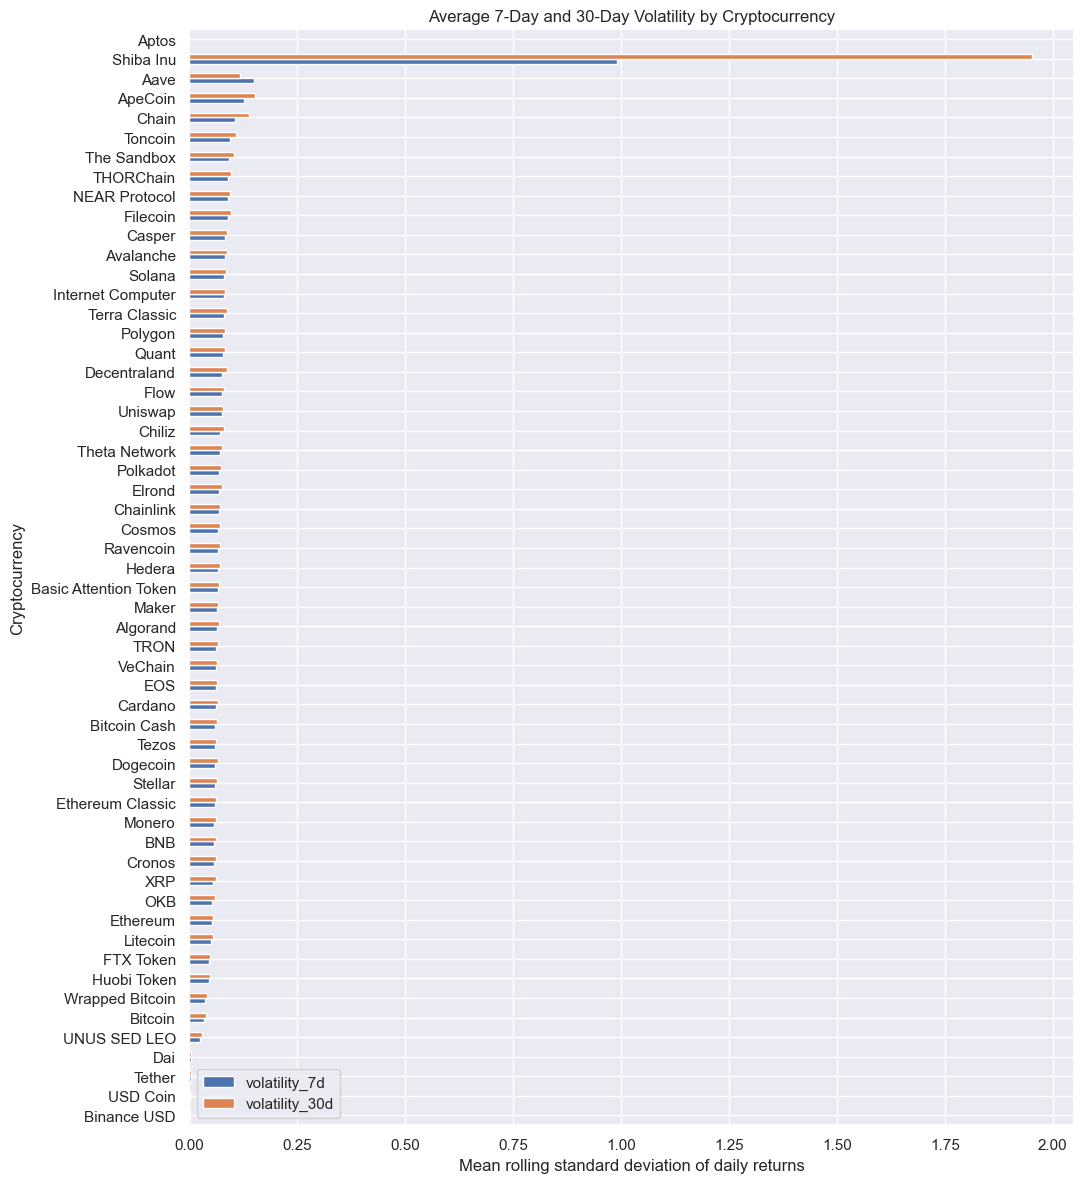

In [17]:
vol_summary.sort_values("volatility_7d").plot(kind="barh", figsize=(11, 12))
plt.title("Average 7-Day and 30-Day Volatility by Cryptocurrency")
plt.xlabel("Mean rolling standard deviation of daily returns")
plt.ylabel("Cryptocurrency")
plt.tight_layout()
plt.show()

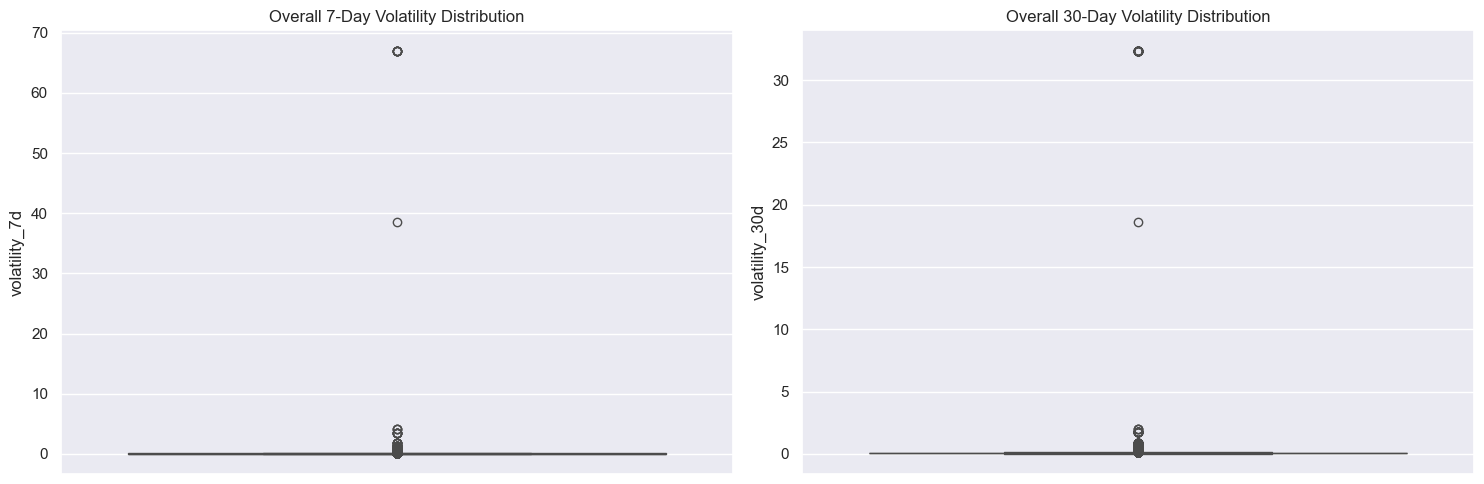

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.boxplot(data=df, y="volatility_7d", ax=axes[0], showfliers=True)
axes[0].set_title("Overall 7-Day Volatility Distribution")
sns.boxplot(data=df, y="volatility_30d", ax=axes[1], showfliers=True)
axes[1].set_title("Overall 30-Day Volatility Distribution")
plt.tight_layout()
plt.show()

## 8. Correlation analysis

Pearson correlation measures linear association. Pooled data across many coins can be affected by differences in price scale and history. Correlation is descriptive; it does not establish causation or prove that a feature improves forecasts.

,open,high,low,close,volume,marketCap,daily_return,volatility_7d,volatility_30d
open,1.000000,0.997202,0.999396,0.999227,0.266756,0.670421,-0.001586,-0.005829,-0.008354
high,0.997202,1.000000,0.996678,0.996989,0.266207,0.667033,-0.001367,-0.005763,-0.008307
low,0.999396,0.996678,1.000000,0.999572,0.264726,0.670297,-0.001350,-0.005893,-0.008389
close,0.999227,0.996989,0.999572,1.000000,0.266575,0.670958,-0.001162,-0.005829,-0.008357
volume,0.266756,0.266207,0.264726,0.266575,1.000000,0.463637,-0.000642,-0.009634,-0.014050
marketCap,0.670421,0.667033,0.670297,0.670958,0.463637,1.000000,-0.001205,-0.005522,-0.008242
daily_return,-0.001586,-0.001367,-0.001350,-0.001162,-0.000642,-0.001205,1.000000,0.366406,0.180260
volatility_7d,-0.005829,-0.005763,-0.005893,-0.005829,-0.009634,-0.005522,0.366406,1.000000,0.481472
volatility_30d,-0.008354,-0.008307,-0.008389,-0.008357,-0.014050,-0.008242,0.180260,0.481472,1.000000


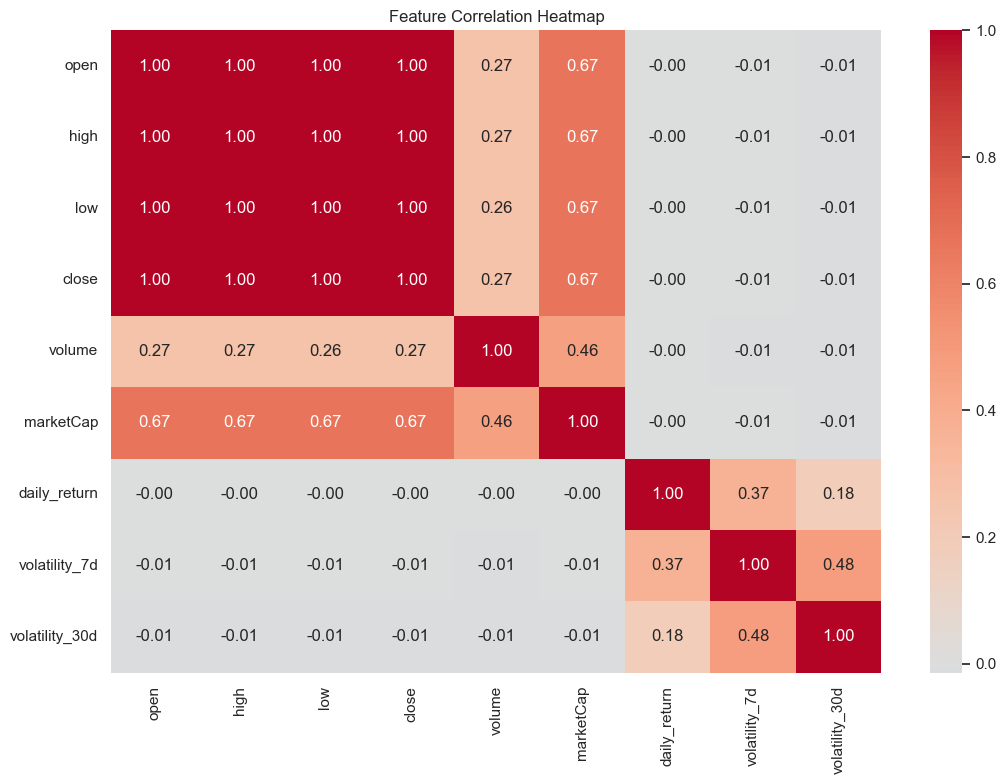

In [19]:
candidate_corr_cols = [
    c for c in [
        "open", "high", "low", "close", "volume", "marketCap",
        "daily_return", "volatility_7d", "volatility_30d"
    ] if c in df.columns
]
corr_matrix = df[candidate_corr_cols].corr(numeric_only=True)
display(corr_matrix)

plt.figure(figsize=(11, 8))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", center=0, fmt=".2f")
plt.title("Feature Correlation Heatmap")
plt.tight_layout()
plt.show()

## 9. Define a one-observation-ahead volatility target

Within each coin, `shift(-1)` assigns the next available row's 7-day volatility to the current row. This is **next observation**, not necessarily next calendar day. We re-sort first so the target is aligned chronologically.

In [20]:
df = df.sort_values(["crypto_name", "date"]).reset_index(drop=True)
df["target_volatility"] = (
    df.groupby("crypto_name", sort=False)["volatility_7d"].shift(-1)
)

display(df[["crypto_name", "date", "volatility_7d", "target_volatility"]].head(12))

,crypto_name,date,volatility_7d,target_volatility
0,Aave,2020-10-02,NaN,NaN
1,Aave,2020-10-03,NaN,NaN
2,Aave,2020-10-04,NaN,NaN
3,Aave,2020-10-05,NaN,NaN
4,Aave,2020-10-06,NaN,NaN
5,Aave,2020-10-07,NaN,NaN
6,Aave,2020-10-08,NaN,38.517966
7,Aave,2020-10-09,38.517966,0.099951
8,Aave,2020-10-10,0.099951,0.100147
9,Aave,2020-10-11,0.100147,0.102326


In [21]:
# Target correlation is a descriptive screening view. Do not include target_volatility in X.
target_corr_cols = [
    c for c in [
        "open", "high", "low", "close", "volume", "marketCap",
        "daily_return", "volatility_7d", "volatility_30d"
    ] if c in df.columns
]
target_corr = df[target_corr_cols + ["target_volatility"]].corr(numeric_only=True)
display(target_corr["target_volatility"].sort_values(ascending=False).to_frame("corr_with_target"))

,corr_with_target
target_volatility,1.000000
volatility_7d,0.839704
volatility_30d,0.413776
daily_return,0.367178
marketCap,-0.005534
high,-0.005754
open,-0.005818
close,-0.005823
low,-0.005891
volume,-0.009604


## 10. Modeling handoff: features, missingness, and a date-based holdout

This section prepares a modeling table but does not fit a model. The sample split uses a **global date cutoff** so rows after the cutoff are held out. For a multi-coin forecasting evaluation, this avoids the issue of splitting a coin-sorted table into train/test chunks that mix calendar periods.

The cutoff is based on the 80th percentile of unique dates. For a stricter real-world backtest, choose a fixed date and consider rolling/expanding-window validation.

In [22]:
FEATURES = ["volatility_7d", "volatility_30d", "daily_return"]
TARGET = "target_volatility"

missing_features = [c for c in FEATURES + [TARGET] if c not in df.columns]
if missing_features:
    raise ValueError(f"Missing required modeling columns: {missing_features}")

model_df = df[["crypto_name", "date"] + FEATURES + [TARGET]].dropna(
    subset=FEATURES + [TARGET]
).copy()

unique_dates = np.sort(model_df["date"].dropna().unique())
if len(unique_dates) < 2:
    raise ValueError("Not enough unique dates for a chronological train/test split.")

cutoff_idx = min(int(len(unique_dates) * 0.8), len(unique_dates) - 1)
cutoff_date = pd.Timestamp(unique_dates[cutoff_idx])

train_df = model_df[model_df["date"] < cutoff_date].copy()
test_df = model_df[model_df["date"] >= cutoff_date].copy()

X_train = train_df[FEATURES]
y_train = train_df[TARGET]
X_test = test_df[FEATURES]
y_test = test_df[TARGET]

print("Cutoff date:", cutoff_date)
print("Train date range:", train_df["date"].min(), "to", train_df["date"].max())
print("Test date range:", test_df["date"].min(), "to", test_df["date"].max())
print("X_train:", X_train.shape, "| y_train:", y_train.shape)
print("X_test:", X_test.shape, "| y_test:", y_test.shape)

Cutoff date: 2020-06-24 00:00:00
Train date range: 2013-06-04 00:00:00 to 2020-06-23 00:00:00
Test date range: 2020-06-24 00:00:00 to 2022-10-16 00:00:00
X_train: (39190, 3) | y_train: (39190,)
X_test: (32050, 3) | y_test: (32050,)


In [23]:
# Verify there is no overlap in calendar dates between training and test sets.
train_dates = set(train_df["date"].unique())
test_dates = set(test_df["date"].unique())
print("Date overlap:", len(train_dates.intersection(test_dates)))
assert train_df["date"].max() < test_df["date"].min()

Date overlap: 0


## 11. EDA conclusions and dashboard handoff

### What this notebook delivers
- Dataset quality and coverage checks.
- Price, return, and volatility exploration.
- Investigation of extreme returns without automatic deletion.
- Correlation analysis.
- A clearly defined one-step-ahead target and date-based holdout table.

### Before dashboard integration
1. Build and validate a model in a separate modeling notebook or Python module.
2. Compare against a simple baseline and report MAE/RMSE (and R² where useful).
3. Use time-aware validation, not random shuffling.
4. Confirm whether the target should mean next available observation or next calendar day.
5. Store preprocessing and model steps reproducibly; save the fitted model only after evaluation.
6. In the dashboard, show the forecast horizon, units, model evaluation period, and caveats.

**Conclusion:** This is a solid EDA and modeling-handoff notebook. It is not itself a production prediction pipeline or a deployed dashboard backend.